# 콘크리트 강도 ANN — 반복 무작위 7:3 성능 검증

계산기 모델과 **별도로** 돌리는 검증용 노트북입니다.

1. 원자료(UCI *Concrete Compressive Strength*, 1,030건)에서 **완전히 같은 행**은 하나만 남기고, **배합·재령이 같은데 강도가 다른 행**은 모두 뺍니다.
2. 남은 데이터를 **무작위로 7:3**으로 나눠, 7로 ANN을 학습하고 3의 배합·재령을 넣어 나온 예측값을 실제 강도와 비교합니다.
3. 이것을 `N_REPEAT`번 반복해 성능의 평균과 범위를 봅니다. 비교로 **배합 기준 7:3**(같은 배합은 한쪽에만)도 같은 횟수만큼 반복합니다.

ANN 구조는 계산기 모델과 같습니다: 입력 = 재료 7종 + 재령(로그 변환), MinMaxScaler → MLPRegressor(은닉층 64, tanh, alpha 0.0001, 학습률 0.01, 조기 종료).

In [1]:
DATA_SOURCE = "auto"      # "auto": UCI 자동 다운로드 / "upload": 직접 올리기
LOCAL_PATH = ""
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip"
N_REPEAT = 1000           # 반복 횟수 (무료 Colab에서 1,000회 × 2가지 방식은 20~40분 정도 걸릴 수 있음)
TEST_SIZE = 0.30
CHECKPOINTS = [10, 30, 50, 100, 200, 300, 500, 1000]   # 반복 횟수별로 결과가 얼마나 안정되는지 볼 지점

In [2]:
import io, zipfile, warnings, subprocess, sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
for pkg, mod in [("xlrd", "xlrd"), ("koreanize-matplotlib", "koreanize_matplotlib")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    pass
plt.rcParams["axes.unicode_minus"] = False
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

NAMES = ["시멘트", "고로슬래그", "플라이애시", "물", "고성능감수제", "굵은골재", "잔골재", "재령", "압축강도"]
MATERIALS, FEATURES = NAMES[:7], NAMES[:8]


def read_table(name, data):
    if str(name).lower().endswith((".xls", ".xlsx")):
        return pd.read_excel(io.BytesIO(data) if isinstance(data, bytes) else data)
    return pd.read_csv(io.BytesIO(data) if isinstance(data, bytes) else data)


def load_raw():
    if LOCAL_PATH:
        return read_table(LOCAL_PATH, LOCAL_PATH)
    if DATA_SOURCE == "auto":
        try:
            import urllib.request
            with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as r:
                z = zipfile.ZipFile(io.BytesIO(r.read()))
            name = next(n for n in z.namelist() if n.lower().endswith(".xls"))
            return read_table(name, z.read(name))
        except Exception as e:
            print("자동 다운로드 실패 → 직접 올려 주세요:", e)
    if IN_COLAB:
        up = colab_files.upload(); name = next(iter(up)); return read_table(name, up[name])
    path = input("파일 경로: ").strip(); return read_table(path, path)


raw = load_raw(); assert raw.shape[1] == 9; raw.columns = NAMES
d1 = raw.drop_duplicates().reset_index(drop=True)
conflict = d1.duplicated(subset=FEATURES, keep=False)
dc = d1[~conflict].reset_index(drop=True)
dc["배합번호"] = dc.groupby(MATERIALS).ngroup() + 1
CLEAN = {"원자료": len(raw), "완전 중복 제외": int(raw.duplicated().sum()), "강도 충돌 행 제외": int(conflict.sum()),
         "강도 충돌 조건 수": int(d1[conflict].groupby(FEATURES).ngroups), "검증용 데이터": len(dc), "배합 수": int(dc["배합번호"].nunique())}
print(CLEAN)

{'원자료': 1030, '완전 중복 제외': 25, '강도 충돌 행 제외': 18, '강도 충돌 조건 수': 9, '검증용 데이터': 987, '배합 수': 426}


## 반복 검증

In [3]:
def make_ann(seed):
    pre = ColumnTransformer([("재료", "passthrough", MATERIALS), ("재령", FunctionTransformer(np.log), ["재령"])])
    return Pipeline([("pre", pre), ("scale", MinMaxScaler()),
                     ("mlp", MLPRegressor(hidden_layer_sizes=(64,), activation="tanh", alpha=1e-4, learning_rate_init=0.01,
                                          max_iter=5000, early_stopping=True, validation_fraction=0.15, n_iter_no_change=50,
                                          random_state=seed))])


def one_run(seed, scheme):
    if scheme == "무작위":
        a, b = train_test_split(np.arange(len(dc)), test_size=TEST_SIZE, random_state=seed)
    else:
        a, b = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=seed).split(dc, groups=dc["배합번호"]))
    m = make_ann(seed).fit(dc.iloc[a][FEATURES], dc.iloc[a]["압축강도"])
    y, p = dc.iloc[b]["압축강도"].values, m.predict(dc.iloc[b][FEATURES]); e = p - y
    return {"방식": scheme, "회차": seed + 1, "학습 건수": len(a), "검증 건수": len(b),
            "R²": r2_score(y, p), "MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)),
            "±5 MPa 이내": np.mean(np.abs(e) <= 5), "±10 MPa 이내": np.mean(np.abs(e) <= 10),
            "상대오차 중앙값": np.median(np.abs(e) / y), "평균 편향": e.mean(),
            "학습 R²": r2_score(dc.iloc[a]["압축강도"], m.predict(dc.iloc[a][FEATURES]))}


runs = Parallel(n_jobs=-1, verbose=0)(delayed(one_run)(s, sch) for sch in ["무작위", "배합 기준"] for s in range(N_REPEAT))
rep = pd.DataFrame(runs)
rep.to_csv("validation_runs.csv", index=False, encoding="utf-8-sig")
print(f"완료: {len(rep)}번 학습·검증 → validation_runs.csv")

완료: 2000번 학습·검증 → validation_runs.csv


## 결과 요약

In [4]:
M = ["R²", "MAE", "RMSE", "±5 MPa 이내", "±10 MPa 이내", "상대오차 중앙값", "평균 편향", "학습 R²"]
def summary(df):
    return pd.DataFrame({"평균": df[M].mean(), "표준편차": df[M].std(), "2.5%": df[M].quantile(0.025),
                         "97.5%": df[M].quantile(0.975), "최소": df[M].min(), "최대": df[M].max()}).round(4)
SUM = {s: summary(rep[rep["방식"] == s]) for s in ["무작위", "배합 기준"]}
for s, t in SUM.items():
    print(f"[{s} 7:3 × {N_REPEAT}회]"); display(t)

[무작위 7:3 × 1000회]


,평균,표준편차,2.5%,97.5%,최소,최대
R²,0.8915,0.0213,0.8485,0.9213,0.7472,0.9347
MAE,3.8543,0.4142,3.2539,4.7495,3.0828,6.1660
RMSE,5.3177,0.4839,4.5499,6.3742,4.1973,7.9638
±5 MPa 이내,0.7287,0.0499,0.6128,0.8047,0.4916,0.8249
±10 MPa 이내,0.9349,0.0216,0.8923,0.9663,0.7845,0.9731
상대오차 중앙값,0.0911,0.0128,0.0721,0.1198,0.0636,0.1570
평균 편향,-0.0065,0.4579,-0.9246,0.8936,-1.7014,1.3776
학습 R²,0.9287,0.0277,0.8716,0.9647,0.7603,0.9759


[배합 기준 7:3 × 1000회]


,평균,표준편차,2.5%,97.5%,최소,최대
R²,0.8490,0.0321,0.7747,0.9013,0.7205,0.9254
MAE,4.5034,0.4776,3.7159,5.5752,3.1156,6.5009
RMSE,6.2463,0.6521,5.0791,7.6137,4.5718,8.6241
±5 MPa 이내,0.6697,0.0526,0.5451,0.7551,0.4695,0.8061
±10 MPa 이내,0.8981,0.0289,0.8293,0.9463,0.7670,0.9637
상대오차 중앙값,0.1054,0.0141,0.0832,0.1394,0.0715,0.1638
평균 편향,-0.0284,0.7839,-1.5626,1.4791,-2.5530,2.5254
학습 R²,0.9268,0.0345,0.8293,0.9685,0.7558,0.9758


## 반복 횟수는 충분한가

반복 횟수를 늘려 가며 **R² 평균**과 **95% 범위(2.5%~97.5%)**가 어떻게 바뀌는지 봅니다. 숫자가 더 이상 거의 움직이지 않으면 충분한 것입니다.
평균의 불확실성(표준오차)은 표준편차 ÷ √반복 횟수로 계산합니다.

,방식,반복 횟수,R² 평균,평균의 표준오차,95% 범위 하한,95% 범위 상한
0,무작위,10,0.8988,0.0048,0.8705,0.9167
1,무작위,30,0.8949,0.0031,0.8635,0.9202
2,무작위,50,0.8926,0.0025,0.8630,0.9202
3,무작위,100,0.8904,0.0022,0.8493,0.9225
4,무작위,200,0.8913,0.0015,0.8485,0.9196
5,무작위,300,0.8915,0.0012,0.8496,0.9199
6,무작위,500,0.8915,0.0010,0.8436,0.9199
7,무작위,1000,0.8915,0.0007,0.8485,0.9213
8,배합 기준,10,0.8588,0.0074,0.8208,0.8870
9,배합 기준,30,0.8536,0.0065,0.7787,0.9083


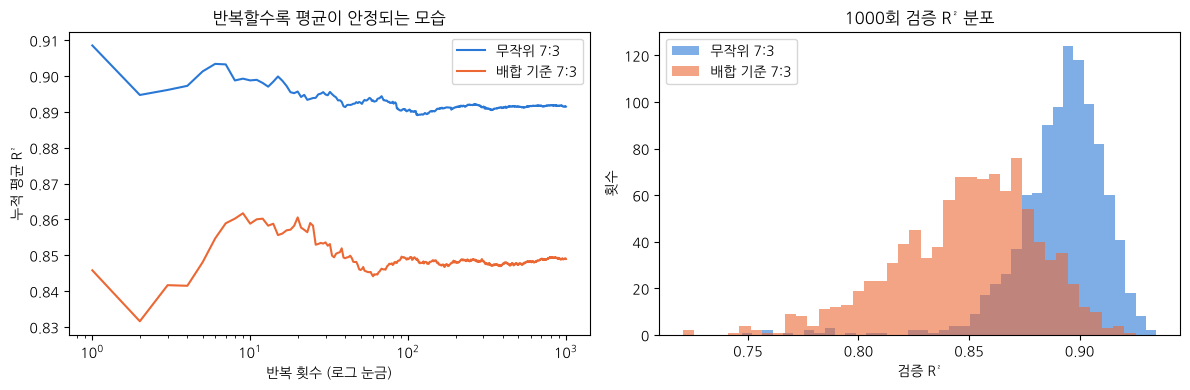

저장: validation_runs.csv, validation_summary.json


In [5]:
conv = []
for s in ["무작위", "배합 기준"]:
    r2 = rep[rep["방식"] == s].sort_values("회차")["R²"].values
    for n in [c for c in CHECKPOINTS if c <= len(r2)]:
        x = r2[:n]
        conv.append({"방식": s, "반복 횟수": n, "R² 평균": x.mean(), "평균의 표준오차": x.std(ddof=1) / np.sqrt(n),
                     "95% 범위 하한": np.quantile(x, 0.025), "95% 범위 상한": np.quantile(x, 0.975)})
conv = pd.DataFrame(conv).round(4)
display(conv)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, c in [("무작위", "#2a78d6"), ("배합 기준", "#eb6834")]:
    r2 = rep[rep["방식"] == s].sort_values("회차")["R²"].values
    n = np.arange(1, len(r2) + 1)
    ax[0].plot(n, np.cumsum(r2) / n, color=c, label=f"{s} 7:3")
    ax[1].hist(r2, bins=40, alpha=0.6, color=c, label=f"{s} 7:3")
ax[0].set_xscale("log"); ax[0].set_xlabel("반복 횟수 (로그 눈금)"); ax[0].set_ylabel("누적 평균 R²"); ax[0].set_title("반복할수록 평균이 안정되는 모습"); ax[0].legend()
ax[1].set_xlabel("검증 R²"); ax[1].set_ylabel("횟수"); ax[1].set_title(f"{N_REPEAT}회 검증 R² 분포"); ax[1].legend()
plt.tight_layout(); plt.show()

out = {"clean": CLEAN, "n": int(N_REPEAT), "summary": {s: t.to_dict() for s, t in SUM.items()}, "convergence": conv.to_dict("records")}
with open("validation_summary.json", "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False)
print("저장: validation_runs.csv, validation_summary.json")